# 08 — COCO: are the changed captions actually *wrong*?

**Why this notebook.** Notebooks 01–07 compare each perturbed caption with the model's **own clean caption**: they measure whether a caption *changed*, not whether it is *wrong* (limitation listed in Section 14 of the report). COCO gives every image about five captions written by different people, so we can check correctness against humans.

**Three experiments**
- **A. Cross-dataset transfer.** The v built on ImageNetV2 in notebook 01, applied to COCO images through the real pipeline (8-bit image file, standard SmolVLM processor). Is v universal across datasets?
- **B. v rebuilt on COCO.** Same `train_uap` as notebook 01, on 500 COCO images. Does building v on the right data matter?
- **C. Scoring against humans.** Every caption (clean, v, random noise) is scored against the human captions:
  1. **changed** (old metric, for comparison with the report): similarity to the clean caption < 0.5;
  2. **CIDEr and BLEU-4**, the standard captioning scores;
  3. **correct / wrong** for each image, with a threshold calibrated on the humans themselves; then the **real attack success rate**: among images the model described correctly, the share that v makes wrong.

**Before running:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. About 35–45 minutes (download ≈ 5, building v ≈ 10, captions ≈ 20).

## 0. Configuration

In [ ]:
# ===================== CONFIG =====================
MODEL_ID   = "HuggingFaceTB/SmolVLM-256M-Instruct"
IMG_SIZE   = 512
PREPROCESS = "pad"            # "pad": keep the whole image, add grey bands | "crop": centre crop, as in notebooks 01-07

N_EVAL     = 500              # COCO images to evaluate (95% CI half-width about ±4 points at 50%)
N_BUILD    = 500              # other COCO images used to build v in experiment B
N_SPLIT    = 100              # of the eval images, how many also go through "splitting on" (17 tiles: slow)

NORM_XI    = 10/255           # same budget as the report
REBUILD_V  = True             # experiment B (about 10 min); False = skip it
EPOCHS     = 5                # notebook 01 used 10; 5 keeps the run shorter (see the training curve)
BATCH      = 8
LR         = 1/255

PROMPT     = "Describe this image in one sentence."    # same prompt as notebook 01
MAX_NEW_TOKENS = 40
CAPTION_SIM_CHANGED = 0.5     # old metric: "changed" if similarity to the clean caption < 0.5
HUMAN_QUANTILE = 0.05         # "correct" threshold = score reached by 95% of human captions

V_URL = ("https://raw.githubusercontent.com/raathi75/EA_universal_perturbation/main/"
         "smol_exp/uap_smolvlm/uap_smolvlm256m_linf10.npy")   # notebook 01's v (ImageNetV2)
SEED = 0
TEST_MODE = False             # True = fake images and a tiny random model, only to check the code runs
# ==================================================

## 1. Setup

In [ ]:
import importlib.util, subprocess, sys
for pkg, name in [("sentence_transformers", "sentence-transformers"), ("pycocoevalcap", "pycocoevalcap")]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", name], check=True)

import os, re, io, json, time, math, random, zipfile, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cpu" and not TEST_MODE:
    raise RuntimeError("No GPU: Runtime -> Change runtime type -> T4 GPU")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
OUT = Path("outputs_coco"); OUT.mkdir(exist_ok=True)     # everything is saved here (Files panel)

Device: cuda


## 2. COCO data

We download the 5,000 validation images of COCO 2017 and their captions. Each image has (at least) five captions written by different people, for example:

- *A man riding a wave on top of a surfboard.*
- *A surfer catching a wave in the ocean.*
- *A person on a surfboard in the water.*
- …

Five people describe the same image in five different ways. That's the point: there is no single "right" caption, so a model caption is judged against all five.

After a fixed shuffle, the first `N_EVAL` images are evaluated and the next `N_BUILD` build v in experiment B. The two sets never overlap.

In [ ]:
DATA = Path("data_coco"); DATA.mkdir(exist_ok=True)
IMG_DIR, CAP_FILE = DATA / "val2017", DATA / "captions_val2017.json"

if TEST_MODE:   # fake COCO: random images of COCO-like sizes, captions from a tiny vocabulary
    IMG_DIR.mkdir(exist_ok=True)
    words = ["a man riding a horse", "a dog on a beach", "a plate of food", "a person holding an umbrella",
             "a cat on a sofa", "a train at a station"]
    imgs, anns = [], []
    for i in range(40):
        w, h = (640, 480) if i % 2 else (480, 640)
        Image.fromarray(np.random.randint(0, 255, (h, w, 3), dtype=np.uint8)).save(IMG_DIR / f"{i:012d}.jpg")
        imgs.append({"id": i, "file_name": f"{i:012d}.jpg"})
        anns += [{"image_id": i, "caption": f"{words[i % 6]} {['outside', 'today', 'here', 'now', 'again'][k]}"}
                 for k in range(5)]
    json.dump({"images": imgs, "annotations": anns}, open(CAP_FILE, "w"))
else:
    if not IMG_DIR.exists():
        print("Downloading images (about 800 MB)...")
        urllib.request.urlretrieve("http://images.cocodataset.org/zips/val2017.zip", DATA / "val2017.zip")
        with zipfile.ZipFile(DATA / "val2017.zip") as z: z.extractall(DATA)
        (DATA / "val2017.zip").unlink()
    if not CAP_FILE.exists():
        print("Downloading captions (about 250 MB, we keep one file)...")
        urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", DATA / "ann.zip")
        with zipfile.ZipFile(DATA / "ann.zip") as z:
            CAP_FILE.write_bytes(z.read("annotations/captions_val2017.json"))
        (DATA / "ann.zip").unlink()

coco = json.load(open(CAP_FILE))
REFS = {}
for a in coco["annotations"]:
    REFS.setdefault(a["image_id"], []).append(a["caption"].strip())
images = sorted([im for im in coco["images"] if len(REFS.get(im["id"], [])) >= 5], key=lambda im: im["id"])
print(len(images), "images with at least 5 human captions")   # expected: 5000

perm = np.random.RandomState(SEED).permutation(len(images))
n_eval, n_build = min(N_EVAL, len(images) // 2), min(N_BUILD, len(images) // 2)
eval_imgs = [images[i] for i in perm[:n_eval]]
build_imgs = [images[i] for i in perm[n_eval:n_eval + n_build]]
refs_eval = [REFS[im["id"]][:5] for im in eval_imgs]        # exactly 5 per image, so every image counts the same
print("eval:", len(eval_imgs), "| build:", len(build_imgs))
print("Example:", *refs_eval[0], sep="\n  - ")

5000 images with at least 5 human captions
eval: 500 | build: 500
Example:
  - a person in a wheel chair swinging a tennis racket
  - There is a lady in a wheelchair holding a tennis racket.
  - Two people are in a wheelchair and only one of them is holding a racket.
  - A woman in a wheelchair holding a tennis racquet.
  - A girl sitting in a wheelchair is playing tennis.


## 3. Making every image 512×512: padding vs cropping

SmolVLM's encoder works on 512×512 squares, but COCO images are rectangles (usually 640×480).

- **Crop** (notebooks 01–07): resize the short side to 512, then cut the middle square. The left and right edges are lost. The human captions describe the *whole* image, so they may mention an object that was cut off, and the model would be marked wrong for something it never saw.
- **Pad** (default here): resize the **long** side to 512, so the whole image fits, then fill the empty bands with grey. Nothing is lost.

One side effect of padding: the grey bands are flat regions, where the report found v most visible. That's acceptable here because every condition uses the same images; set `PREPROCESS = "crop"` to check the conclusions don't depend on it.

decoding:   0%|          | 0/500 [00:00<?, ?it/s]

decoding:   0%|          | 0/500 [00:00<?, ?it/s]

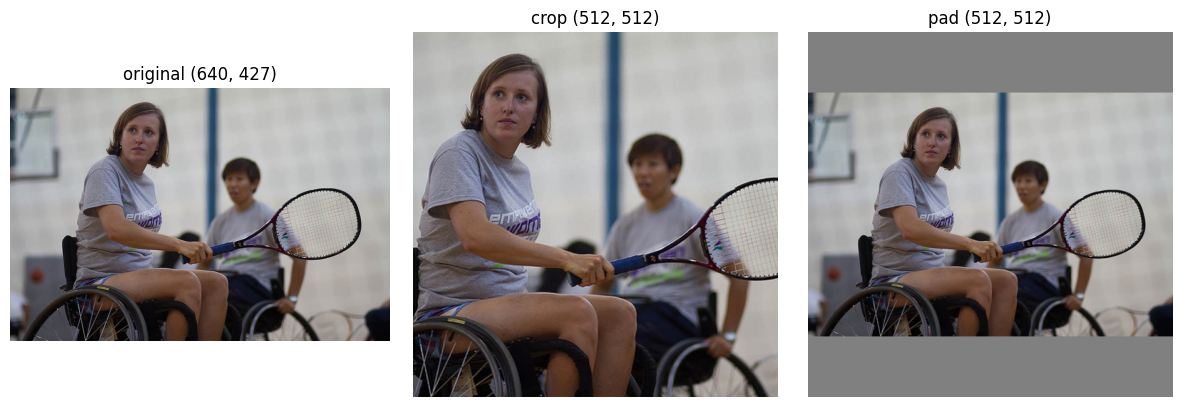

In [ ]:
GREY = (128, 128, 128)

def to_square(img, size=IMG_SIZE, mode=PREPROCESS):
    w, h = img.size
    if mode == "crop":
        s = size / min(w, h)
        img = img.resize((round(w * s), round(h * s)), Image.BICUBIC)
        l, t = (img.width - size) // 2, (img.height - size) // 2
        return img.crop((l, t, l + size, t + size))
    s = size / max(w, h)                                     # "pad": the long side becomes 512
    img = img.resize((round(w * s), round(h * s)), Image.BICUBIC)
    canvas = Image.new("RGB", (size, size), GREY)
    canvas.paste(img, ((size - img.width) // 2, (size - img.height) // 2))
    return canvas

def load_uint8(imgs):      # (N, 3, 512, 512) uint8, like notebook 01
    arr = [np.asarray(to_square(Image.open(IMG_DIR / im["file_name"]).convert("RGB"))) for im in tqdm(imgs, desc="decoding")]
    return torch.from_numpy(np.stack(arr)).permute(0, 3, 1, 2).contiguous()

E_u8 = load_uint8(eval_imgs)
B_u8 = load_uint8(build_imgs) if REBUILD_V else None

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
raw = Image.open(IMG_DIR / eval_imgs[0]["file_name"]).convert("RGB")
for a, (title, im) in zip(ax, [("original", raw), ("crop", to_square(raw, mode="crop")), ("pad", to_square(raw, mode="pad"))]):
    a.imshow(im); a.set_title(f"{title} {im.size}"); a.axis("off")
plt.tight_layout(); plt.show()

## 4. Model and the functions from notebooks 01–02

Same model, same normalisation, same real pipeline as your teammate's notebooks:
- `to_pil_u8` adds v to the image **in pixel space**, then rounds to whole values 0–255: an ordinary 8-bit image file, which is all a real attacker can hand over;
- `gen_pipeline` sends those images through the **standard SmolVLM processor**, with image splitting off (1 tile) or on (16 local tiles + 1 global tile), and generates captions greedily;
- `train_uap` is notebook 01's training loop.

In [ ]:
if TEST_MODE:
    from transformers import SmolVLMVisionConfig
    from transformers.models.smolvlm.modeling_smolvlm import SmolVLMVisionTransformer
    VIS = SmolVLMVisionTransformer(SmolVLMVisionConfig(hidden_size=32, num_hidden_layers=2, num_attention_heads=2,
                                   intermediate_size=64, image_size=IMG_SIZE, patch_size=16)).to(DEVICE).eval()
    MEAN = STD = torch.tensor([0.5, 0.5, 0.5], device=DEVICE).view(1, 3, 1, 1)
    processor = model = None
else:
    from transformers import AutoProcessor, AutoModelForImageTextToText
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    processor.tokenizer.padding_side = "left"
    model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=torch.float32).to(DEVICE).eval()
    VIS = model.model.vision_model
    ip = processor.image_processor
    MEAN = torch.tensor(ip.image_mean, device=DEVICE).view(1, 3, 1, 1)
    STD = torch.tensor(ip.image_std, device=DEVICE).view(1, 3, 1, 1)
for p in VIS.parameters():
    p.requires_grad_(False)

def to01(u8): return u8.to(DEVICE).float().div(255)
def norm(x01): return (x01 - MEAN) / STD
def visual_tokens(x01): return VIS(pixel_values=norm(x01)).last_hidden_state
def token_cosine(a, b): return F.cosine_similarity(a, b, dim=-1).mean(dim=1)

def chat(prompt):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    return processor.apply_chat_template(msgs, add_generation_prompt=True)

def to_pil_u8(u8, pert=None):
    x = u8.float()
    if pert is not None:
        x = x + pert[0].cpu() * 255
    x = x.round().clamp(0, 255).to(torch.uint8)
    return Image.fromarray(x.permute(1, 2, 0).numpy())

@torch.no_grad()
def gen_pipeline(u8_batch, prompt, pert, split, bs=8):
    if TEST_MODE:   # fake captions that depend on the image, so the scoring code can be tested
        words = ["a man riding a horse", "a dog on a beach", "a plate of food", "a cat on a sofa"]
        return [words[int(np.asarray(to_pil_u8(u, pert))[::64, ::64].mean()) % 4] for u in u8_batch], 1
    outs, tiles = [], None
    for i in range(0, len(u8_batch), bs):
        pils = [to_pil_u8(u, pert) for u in u8_batch[i:i + bs]]
        inp = processor(text=[chat(prompt)] * len(pils), images=[[p] for p in pils],
                        do_image_splitting=split, return_tensors="pt", padding=True).to(DEVICE)
        tiles = inp["pixel_values"].shape[1]
        g = model.generate(**inp, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        outs += processor.batch_decode(g[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs], tiles

def train_uap(images_u8, xi=NORM_XI, epochs=EPOCHS, bs=BATCH, lr=LR, tag="uap_coco"):
    v = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE, requires_grad=True)
    opt = torch.optim.Adam([v], lr=lr)
    hist, t0 = [], time.time()
    for ep in range(epochs):
        losses = []
        for idx in torch.randperm(len(images_u8)).split(bs):
            x = to01(images_u8[idx])
            with torch.no_grad():
                z_clean = visual_tokens(x)
            loss = token_cosine(z_clean, visual_tokens((x + v).clamp(0, 1))).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                v.clamp_(-xi, xi)
            losses.append(loss.item())
        hist.append(float(np.mean(losses)))
        print(f"{tag} epoch {ep + 1}: mean token cosine on build set = {hist[-1]:.3f} ({(time.time() - t0) / 60:.1f} min)")
        torch.save(v.detach().cpu(), OUT / f"{tag}_ckpt.pt")
    return v.detach(), hist

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/516 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.3k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  513MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

## 5. The perturbations

- **v ImageNetV2**: notebook 01's v, downloaded from the group repo (experiment A).
- **v COCO**: rebuilt here on 500 COCO images (experiment B).
- **random ±ε**: every pixel moved by +10/255 or −10/255 at random. Same size as v, but no direction. It tells us how much of any change is just "the image got noisier".

v ImageNetV2: (1, 3, 512, 512) | ||v||_inf = 10.0 /255
uap_coco epoch 1: mean token cosine on build set = 0.271 (2.0 min)
uap_coco epoch 2: mean token cosine on build set = -0.180 (4.0 min)
uap_coco epoch 3: mean token cosine on build set = -0.251 (6.1 min)
uap_coco epoch 4: mean token cosine on build set = -0.288 (8.2 min)
uap_coco epoch 5: mean token cosine on build set = -0.304 (10.2 min)


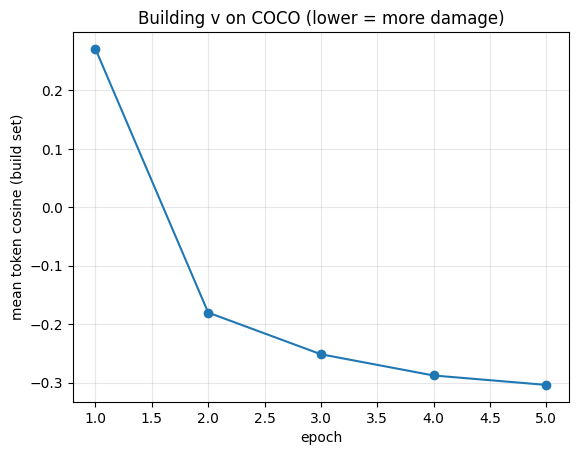

In [ ]:
v_path = OUT / "uap_smolvlm256m_linf10.npy"
if not v_path.exists():
    urllib.request.urlretrieve(V_URL, v_path)
v_imnet = torch.from_numpy(np.load(v_path)).to(DEVICE).float()
torch.manual_seed(SEED)
v_rand = NORM_XI * torch.sign(torch.randn_like(v_imnet))
print("v ImageNetV2:", tuple(v_imnet.shape), "| ||v||_inf =", round(v_imnet.abs().max().item() * 255, 2), "/255")

PERTS = {"random ±ε": v_rand, "v ImageNetV2": v_imnet}
if REBUILD_V:
    v_coco, hist = train_uap(B_u8)
    np.save(OUT / "uap_smolvlm256m_linf10_coco.npy", v_coco.cpu().numpy())
    PERTS["v COCO"] = v_coco
    plt.plot(range(1, len(hist) + 1), hist, marker="o"); plt.xlabel("epoch"); plt.ylabel("mean token cosine (build set)")
    plt.title("Building v on COCO (lower = more damage)"); plt.grid(alpha=.3); plt.show()

## 6. Captions

For every condition (clean + each perturbation): all `N_EVAL` images with splitting **off** (1 tile), and the first `N_SPLIT` with splitting **on** (17 tiles, SmolVLM's default, much slower). Captions are saved to a CSV after each condition, so nothing is lost if the session stops.

In [ ]:
CAPS = {}   # CAPS[(split, condition)] = list of captions
t0 = time.time()
for split, n in [(False, len(E_u8)), (True, min(N_SPLIT, len(E_u8)))]:
    for cond, pert in [("clean", None)] + list(PERTS.items()):
        CAPS[(split, cond)], tiles = gen_pipeline(E_u8[:n], PROMPT, pert, split)
        print(f"splitting {'on ' if split else 'off'} | {cond:13s} | {n} images, {tiles} tile(s) | {(time.time() - t0) / 60:.1f} min")
        pd.DataFrame({f"{'on' if s else 'off'} | {c}": pd.Series(v) for (s, c), v in CAPS.items()}).to_csv(OUT / "captions.csv", index=False)

splitting off | clean         | 500 images, 1 tile(s) | 2.4 min
splitting off | random ±ε     | 500 images, 1 tile(s) | 4.7 min
splitting off | v ImageNetV2  | 500 images, 1 tile(s) | 7.2 min
splitting off | v COCO        | 500 images, 1 tile(s) | 9.6 min
splitting on  | clean         | 100 images, 17 tile(s) | 12.2 min
splitting on  | random ±ε     | 100 images, 17 tile(s) | 14.8 min
splitting on  | v ImageNetV2  | 100 images, 17 tile(s) | 17.5 min
splitting on  | v COCO        | 100 images, 17 tile(s) | 20.1 min


## 7. Scoring against humans

### 7a. Old metric: did the caption change?

Same as the report: MiniLM similarity between clean and perturbed caption < 0.5. With a 95% Wilson confidence interval.

In [ ]:
if TEST_MODE:   # stand-in for MiniLM: bag of words, normalised
    def embed(texts):
        e = torch.zeros(len(texts), 512)
        for i, t in enumerate(texts):
            for w in re.findall(r"[a-z]+", t.lower()):
                e[i, hash(w) % 512] += 1
        return F.normalize(e, dim=-1)
else:
    from sentence_transformers import SentenceTransformer
    st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
    def embed(texts):
        return st.encode(texts, convert_to_tensor=True, normalize_embeddings=True).cpu()

def wilson(k, n, z=1.96):
    if n == 0: return "n/a"
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return f"{100 * p:.1f}% ({100 * (c - h):.1f}–{100 * (c + h):.1f})"

def changed(split, cond):
    a, b = embed(CAPS[(split, "clean")]), embed(CAPS[(split, cond)])
    return (a * b).sum(-1) < CAPTION_SIM_CHANGED

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

### 7b. CIDEr and BLEU-4

The standard captioning scores, computed over the whole set of captions against the five human references (higher = closer to what humans wrote). Captions are lower-cased and stripped of punctuation first.
- **BLEU-4** counts shared word sequences of 1 to 4 words, from 0 to 1.
- **CIDEr** does the same but gives more weight to informative words ("surfboard") than to common ones ("a", "the"). It's the main score in captioning papers: the C-PGC paper reports BLIP dropping from 133.3 to 62.5 under attack.

We report them ×100, as papers usually do.

In [ ]:
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.bleu.bleu import Bleu

def tok(s):
    return " ".join(re.findall(r"[a-z0-9]+", s.lower()))

def coco_scores(caps, refs):
    gts = {i: [tok(r) for r in rs] for i, rs in enumerate(refs)}
    res = {i: [tok(c) if tok(c) else "empty"] for i, c in enumerate(caps)}
    cider, _ = Cider().compute_score(gts, res)
    bleu, _ = Bleu(4).compute_score(gts, res, verbose=0)
    return 100 * cider, 100 * bleu[3]

### 7c. Correct or wrong, image by image

**The score of a caption** = its MiniLM similarity to the closest human caption. To be fair, we compare it with 4 of the 5 human captions at a time, and average over the 5 possible choices of 4.

**The threshold, calibrated on humans.** Each human caption is scored the same way against the 4 *other* human captions. Humans are correct by definition, so we set the threshold at the score that 95% of human captions reach. A model caption below it is less similar to the references than almost any human caption: we call it **wrong**.

Human captions vs the other humans: median 0.74; threshold (score reached by 95% of them) = 0.50


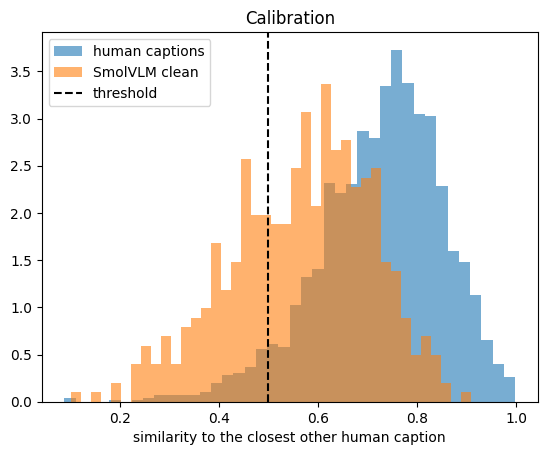

In [ ]:
def loo_scores(cand_emb, ref_emb):
    # cand_emb (N, d), ref_emb (N, 5, d) -> for each image, mean over k of max similarity to the refs other than k
    S = torch.einsum("nd,nkd->nk", cand_emb, ref_emb)
    return torch.stack([S[:, [j for j in range(5) if j != k]].max(1).values for k in range(5)], 1).mean(1)

REF_EMB = embed([r for rs in refs_eval for r in rs]).view(len(refs_eval), 5, -1)

human = []
for k in range(5):        # human caption k against the 4 others
    others = [j for j in range(5) if j != k]
    human.append(torch.einsum("nd,njd->nj", REF_EMB[:, k], REF_EMB[:, others]).max(1).values)
human = torch.stack(human, 1).flatten()
THRESHOLD = torch.quantile(human, HUMAN_QUANTILE).item()
print(f"Human captions vs the other humans: median {human.median():.2f}; "
      f"threshold (score reached by {100 * (1 - HUMAN_QUANTILE):.0f}% of them) = {THRESHOLD:.2f}")

def correct(split, cond):
    n = len(CAPS[(split, cond)])
    return loo_scores(embed(CAPS[(split, cond)]), REF_EMB[:n]) >= THRESHOLD

plt.hist(human.numpy(), bins=40, alpha=.6, label="human captions", density=True)
plt.hist(loo_scores(embed(CAPS[(False, "clean")]), REF_EMB).numpy(), bins=40, alpha=.6, label="SmolVLM clean", density=True)
plt.axvline(THRESHOLD, color="k", ls="--", label="threshold"); plt.xlabel("similarity to the closest other human caption")
plt.legend(); plt.title("Calibration"); plt.show()

## 8. Results

### 8a. Summary table

For each condition:
- **changed**: the old metric of the report;
- **CIDEr / BLEU-4**: closeness to the human captions;
- **correct**: share of captions above the human threshold;
- **real attack success**: among the images whose **clean** caption was correct, the share whose perturbed caption is **wrong**. This is the number the report was missing.

In [ ]:
rows = []
for split in [False, True]:
    ok_clean = correct(split, "clean")
    n = len(ok_clean)
    for cond in ["clean"] + list(PERTS):
        cider, bleu4 = coco_scores(CAPS[(split, cond)], refs_eval[:n])
        ok = correct(split, cond)
        row = {"splitting": "on" if split else "off", "condition": cond, "images": n,
               "CIDEr": round(cider, 1), "BLEU-4": round(bleu4, 1),
               "correct": f"{100 * ok.float().mean():.1f}%"}
        if cond != "clean":
            ch = changed(split, cond)
            broken = (ok_clean & ~ok)
            row["changed (old metric)"] = wilson(int(ch.sum()), n)
            row["real attack success"] = wilson(int(broken.sum()), int(ok_clean.sum()))
        rows.append(row)
SUMMARY = pd.DataFrame(rows).fillna("")
SUMMARY.to_csv(OUT / "summary.csv", index=False)
SUMMARY

,splitting,condition,images,CIDEr,BLEU-4,correct,changed (old metric),real attack success
0,off,clean,500,20.4,6.6,68.6%,,
1,off,random ±ε,500,23.3,7.4,69.2%,2.6% (1.5–4.4),12.2% (9.2–16.1)
2,off,v ImageNetV2,500,2.1,0.9,4.2%,91.0% (88.2–93.2),95.3% (92.6–97.1)
3,off,v COCO,500,0.8,0.4,1.6%,96.2% (94.1–97.6),98.3% (96.2–99.2)
4,on,clean,100,13.5,5.6,74.0%,,
5,on,random ±ε,100,13.8,5.4,75.0%,0.0% (0.0–3.7),10.8% (5.6–19.9)
6,on,v ImageNetV2,100,5.5,0.0,14.0%,70.0% (60.4–78.1),82.4% (72.2–89.4)
7,on,v COCO,100,4.2,2.0,6.0%,89.0% (81.4–93.7),91.9% (83.4–96.2)


### 8b. Changed ≠ wrong: where do the changed captions go?

Only images whose clean caption was **correct** (splitting off). Each one falls in exactly one box:
- **unchanged**: v had no effect on the caption;
- **changed but still correct**: v changed the wording, the caption still matches the humans (a harmless change);
- **changed and wrong**: a real attack success;
- **unchanged but wrong**: rare; the caption barely moved but slipped under the threshold.

In [ ]:
rows = []
ok_clean = correct(False, "clean")
for cond in PERTS:
    ch, ok = changed(False, cond)[ok_clean], correct(False, cond)[ok_clean]
    n = int(ok_clean.sum())
    rows.append({"condition": cond, "images (clean correct)": n,
                 "unchanged": f"{100 * (~ch & ok).float().mean():.1f}%",
                 "changed but still correct": f"{100 * (ch & ok).float().mean():.1f}%",
                 "changed and wrong": f"{100 * (ch & ~ok).float().mean():.1f}%",
                 "unchanged but wrong": f"{100 * (~ch & ~ok).float().mean():.1f}%"})
BREAKDOWN = pd.DataFrame(rows)
BREAKDOWN.to_csv(OUT / "breakdown.csv", index=False)
BREAKDOWN

,condition,images (clean correct),unchanged,changed but still correct,changed and wrong,unchanged but wrong
0,random ±ε,343,87.2%,0.6%,1.2%,11.1%
1,v ImageNetV2,343,4.4%,0.3%,92.1%,3.2%
2,v COCO,343,1.7%,0.0%,96.2%,2.0%


### 8c. The "person in a white shirt" caption

On ImageNetV2, about one perturbed caption in six became "a person wearing a white shirt". COCO has people in many images, so this caption can be **accidentally right**. We count it, and check how often the human captions mention a person.

In [ ]:
PERSON = re.compile(r"\b(man|men|woman|women|person|people|boy|girl|child|children|kid|kids|player|guy|lady|someone)\b")
has_person = torch.tensor([any(PERSON.search(r.lower()) for r in rs) for rs in refs_eval])
print(f"Images whose human captions mention a person: {100 * has_person.float().mean():.0f}%\n")
for cond in PERTS:
    caps = CAPS[(False, cond)]
    ws = torch.tensor([bool(re.search(r"white shirt", c.lower())) for c in caps])
    ok = correct(False, cond)
    if ws.sum() == 0:
        print(f"{cond:13s}: no 'white shirt' caption"); continue
    print(f"{cond:13s}: {int(ws.sum())} 'white shirt' captions ({100 * ws.float().mean():.1f}%); "
          f"{int((ws & has_person).sum())} on images with a person; {int((ws & ok).sum())} scored correct")

Images whose human captions mention a person: 51%

random ±ε    : no 'white shirt' caption
v ImageNetV2 : 45 'white shirt' captions (9.0%); 24 on images with a person; 0 scored correct
v COCO       : 9 'white shirt' captions (1.8%); 4 on images with a person; 0 scored correct


### 8d. Examples to read yourself (the numbers are only as good as the metric)

In [ ]:
def show(cond, mask, title, k=4):
    idx = torch.nonzero(mask).flatten()[:k].tolist()
    print(f"=== {cond} — {title} ({int(mask.sum())} images)")
    for i in idx:
        print(f"  human : {refs_eval[i][0]}")
        print(f"  clean : {CAPS[(False, 'clean')][i]}")
        print(f"  {cond[:6]:6s}: {CAPS[(False, cond)][i]}\n")

cond = "v COCO" if "v COCO" in PERTS else "v ImageNetV2"
ch, ok = changed(False, cond), correct(False, cond)
show(cond, ok_clean & ch & ok, "changed but still correct")
show(cond, ok_clean & ch & ~ok, "changed and wrong")

=== v COCO — changed but still correct (0 images)
=== v COCO — changed and wrong (330 images)
  human : A kitchen has wooden cabinets and black countertops.
  clean : In this image I can see the kitchen and I can see the cupboards, the rack, the sink, the window and the trees.
  v COCO: againov again again again again again again again again again again again again again again again again again again again again again again again again again again again again again again again again again again again again again again

  human : A person on a board holding a para sail rope over a snow field.
  clean : In this image we can see a person flying in the air and there is a parachute. In the background there are trees.
  v COCO: butun army>
 basque time, atomicidece, and>
, and> teeth before explosioner,> teeth,> teeth,> teeth,> muscles,> teeth,>

  human : A vase filled with red and orange flowers.
  clean : In this image we can see a glass vase on the floor.
  v COCO: This image is a graphi

## 9. How to read the results

| If you see… | It means… |
|---|---|
| v ImageNetV2 changes about as many COCO captions as in the report (≈70%, splitting off) | v is universal across datasets, not only across images |
| v COCO clearly beats v ImageNetV2 | building v on the target data matters: a weaker form of universality |
| "real attack success" well below "changed" | many changes are harmless rewordings: the report's numbers overstate the real damage |
| CIDEr drops strongly with v, barely with random noise | the damage is specific to v, measured with the field's standard score |
| many "white shirt" captions scored correct on images with people | the dominant caption is sometimes right by luck: "changed" and "fooled" are not the same |

**Limits to write in the report.**
- "Correct" is decided by a sentence-similarity model calibrated on humans, not by a human. Read the examples in 8d, and if possible label 50 of them by hand, as in Section 10 of the report.
- COCO captions are short and factual; SmolVLM's captions are often longer. Long captions get lower BLEU/CIDEr even when right, which is why we compare conditions with each other, not with published numbers.
- One seed; splitting on is measured on `N_SPLIT` images only.

In [ ]:
json.dump({"config": {k: globals()[k] for k in ["MODEL_ID", "PREPROCESS", "N_EVAL", "N_BUILD", "N_SPLIT", "NORM_XI",
                                                  "EPOCHS", "PROMPT", "CAPTION_SIM_CHANGED", "HUMAN_QUANTILE", "SEED"]},
           "threshold": THRESHOLD,
           "summary": SUMMARY.to_dict(orient="records"),
           "breakdown": BREAKDOWN.to_dict(orient="records")},
          open(OUT / "results_coco.json", "w"), indent=2)
print("Saved in", OUT, ":", sorted(p.name for p in OUT.iterdir()))

Saved in outputs_coco : ['breakdown.csv', 'captions.csv', 'results_coco.json', 'summary.csv', 'uap_coco_ckpt.pt', 'uap_smolvlm256m_linf10.npy', 'uap_smolvlm256m_linf10_coco.npy']
